# Evaluating ChatGPT, Gemini, and Claude in Generating Unit Tests for Python
**Advanced Software Engineering (ICTS 6302)** — Ameera Nimer Alanqar (220252245)


## 0. Complete Experimental Workflow

In [ ]:

# Import standard libraries and utilities required for the experimental pipeline.
from __future__ import annotations

import argparse
import ast
import json
import os
import re
import shutil
import sqlite3
import subprocess
import sys
import time
import xml.etree.ElementTree as ET
from concurrent.futures import ThreadPoolExecutor, as_completed
from dataclasses import dataclass, field
from pathlib import Path

# =============================================================================
# 0. EXPERIMENT CONFIGURATION
# =============================================================================

IN_COLAB = "google.colab" in sys.modules or os.path.exists("/content")


@dataclass
class Config:
    project_dir: Path = Path("/content/drive/MyDrive/SoftwareEng/FinalProject1")
    work_dir: Path = Path("/content/ase_workspace") if IN_COLAB else Path("./ase_workspace")

    models: tuple = ("chatgpt", "gemini", "claude")
    n_tasks: int = 25
    dataset_name: str = "openai/openai_humaneval"

    suite_timeout: int = 120       # Maximum execution time per test suite (seconds)
    test_timeout: int = 10         # Maximum execution time per individual test (seconds)
    mutation_timeout: int = 900    # Maximum execution time for each mutation testing run (seconds)
    max_workers: int = max(1, (os.cpu_count() or 2))

    # Define project directory paths
    solutions_dir: Path = field(init=False)
    prompts_dir: Path = field(init=False)
    tests_dir: Path = field(init=False)
    raw_dir: Path = field(init=False)
    results_dir: Path = field(init=False)
    figures_dir: Path = field(init=False)
    logs_dir: Path = field(init=False)

    def __post_init__(self):
        self.project_dir = Path(self.project_dir).resolve()
        self.work_dir = Path(self.work_dir).resolve()
        self.solutions_dir = self.project_dir / "solutions"
        self.prompts_dir = self.project_dir / "prompts"
        self.tests_dir = self.project_dir / "generated_tests"
        self.raw_dir = self.project_dir / "raw_responses"
        self.results_dir = self.project_dir / "results"
        self.figures_dir = self.results_dir / "figures"
        self.logs_dir = self.results_dir / "logs"

    def ensure_dirs(self) -> None:
        folders = [
            self.solutions_dir,
            self.prompts_dir,
            self.results_dir,
            self.figures_dir,
            self.logs_dir,
            self.work_dir
            ]
        for m in self.models:
            folders += [self.tests_dir / m, self.raw_dir / m]
        for f in folders:
            f.mkdir(parents=True, exist_ok=True)

    @property
    def task_ids(self) -> list[str]:
        return [f"task_{i:03d}" for i in range(self.n_tasks)]

    # Define output paths for evaluation results
    @property
    def static_csv(self): return self.results_dir / "static_metrics.csv"
    @property
    def execution_csv(self): return self.results_dir / "execution_results.csv"
    @property
    def mutation_csv(self): return self.results_dir / "mutation_results.csv"
    @property
    def per_suite_csv(self): return self.results_dir / "per_suite_results.csv"
    @property
    def summary_csv(self): return self.results_dir / "summary_by_model.csv"
    @property
    def descriptive_csv(self): return self.results_dir / "descriptive_statistics.csv"
    @property
    def stats_csv(self): return self.results_dir / "statistical_tests.csv"
    @property
    def changes_csv(self): return self.results_dir / "manual_changes_log.csv"

# Define a standardized prompt template used across all LLM assistants.
PROMPT_TEMPLATE = """Generate Python unit tests for the following function.

Task ID: {task_id}
Function name: {entry_point}

Function code:
{source_code}

Requirements:
- Use pytest.
- Import the function from solutions.{task_id}.
- Write independent test functions whose names start with test_.
- Cover normal cases, edge cases, and boundary cases.
- Do not modify the original function.
- Return ONLY executable Python test code."""


# =============================================================================
# HELPER FUNCTIONS
# =============================================================================

# Display timestamped progress messages.
def log(msg: str) -> None:
    print(f"[{time.strftime('%H:%M:%S')}] {msg}", flush=True)

# Display a formatted section heading.
def banner(title: str) -> None:
    print("\n" + "=" * 78 + f"\n {title}\n" + "=" * 78, flush=True)

# Install the required Python packages.
def pip_install(packages: list[str]) -> None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *packages], check=True)

# Construct the path to a model's test file for a specific task.
def test_file_for(cfg: Config, model: str, task_id: str) -> Path:
    return cfg.tests_dir / model / f"test_{task_id}.py"

# Perform safe division, returning a default value when the denominator is zero.
def safe_div(a: float, b: float, default: float = 0.0) -> float:
    return a / b if b else default


# =============================================================================
# 1. SETUP
# =============================================================================

def stage_setup(cfg: Config) -> None:
    banner("STAGE 1 - Setup")

    # Mount Google Drive when running in Colab and the project is stored there.
    if IN_COLAB and str(cfg.project_dir).startswith("/content/drive"):
        try:
            from google.colab import drive  # type: ignore
            if not Path("/content/drive/MyDrive").exists():
                drive.mount("/content/drive")
        except Exception as exc:  # pragma: no cover
            log(f"Google Drive not mounted: {exc}")
    # Install the libraries required for the experimental pipeline.
    log("Installing dependencies ...")
    pip_install(["datasets", "pytest", "pytest-cov", "pytest-timeout",
                 "mutmut==2.5.1", "pandas", "matplotlib", "scipy"])

    # Create the required project and output directories.
    cfg.ensure_dirs()
    log(f"Project folder : {cfg.project_dir}")
    log(f"Work folder    : {cfg.work_dir}")


# =============================================================================
# 2. BENCHMARK PREPARATION
# =============================================================================

def stage_prepare(cfg: Config) -> None:
    banner("STAGE 2 - Benchmark preparation (HumanEval)")
    from datasets import load_dataset

    # Load the HumanEval benchmark and create the required directories.
    dataset = load_dataset(cfg.dataset_name, split="test")
    cfg.solutions_dir.mkdir(parents=True, exist_ok=True)
    cfg.prompts_dir.mkdir(parents=True, exist_ok=True)

    rows = []
    for i, task in enumerate(dataset.select(range(cfg.n_tasks))):
        task_id = f"task_{i:03d}"
        source_code = task["prompt"] + task["canonical_solution"]

        # Verify each reference solution using HumanEval's original test cases.
        namespace: dict = {}
        exec(source_code + "\n" + task["test"], namespace)
        namespace["check"](namespace[task["entry_point"]])

        # Save the reference solution and generate the corresponding LLM prompt.
        (cfg.solutions_dir / f"{task_id}.py").write_text(source_code, encoding="utf-8")


        prompt = PROMPT_TEMPLATE.format(task_id=task_id, entry_point=task["entry_point"],source_code=source_code.strip())
        (cfg.prompts_dir / f"{task_id}.txt").write_text(prompt, encoding="utf-8")

        # Record benchmark task metadata and reference solution size.
        rows.append({
            "Task": task_id,
            "HumanEval_ID": task["task_id"],
            "Entry_Point": task["entry_point"],
            "Solution_LOC": len([l for l in source_code.splitlines() if l.strip()])
            })

    # Create the solutions package and export the benchmark task metadata.
    (cfg.solutions_dir / "__init__.py").write_text("", encoding="utf-8")

    import pandas as pd
    pd.DataFrame(rows).to_csv(cfg.results_dir / "benchmark_tasks.csv", index=False)
    log(f"{len(rows)} tasks saved (all reference solutions verified).")
    log(f"Next step: paste each assistant's first response into "
        f"generated_tests/<model>/test_task_XXX.py")


# =============================================================================
# 3. NORMALIZATION OF COLLECTED TEST SUITES
# =============================================================================

# Match Python code blocks enclosed in Markdown fences.
FENCE_RE = re.compile(r"```[ \t]*(?:python|py|python3)?[ \t]*\n(.*?)```", re.S | re.I)


def extract_code(text: str) -> tuple[str, list[str]]:
    # Extract executable Python code, removing only Markdown code fences and BOM without modifying test logic.
    changes = []
    blocks = FENCE_RE.findall(text)
    if blocks:
        code = "\n\n".join(b.strip("\n") for b in blocks)
        changes.append(f"Removed markdown fences ({len(blocks)} code block(s))")
    else:
        code = text
    if code.startswith("\ufeff"):
        code = code.lstrip("\ufeff")
        changes.append("Removed BOM")
    if not code.endswith("\n"):
        code += "\n"
    return code, changes


def stage_clean(cfg: Config) -> None:
    banner("STAGE 3 - Normalising collected test suites")
    import pandas as pd

    log_rows, missing = [], []
    for model in cfg.models:
        for task_id in cfg.task_ids:
            path = test_file_for(cfg, model, task_id)

            # Record missing test suites and skip further processing.
            if not path.exists():
                missing.append(f"{model}/{path.name}")
                continue

            # Read the collected response and preserve its original version.
            original = path.read_text(encoding="utf-8", errors="replace")
            backup = cfg.raw_dir / model / path.name
            backup.parent.mkdir(parents=True, exist_ok=True)
            if not backup.exists():               # Keep the first collected version
                backup.write_text(original, encoding="utf-8")

            # Extract executable code and check its syntax.
            code, changes = extract_code(original)
            try:
                ast.parse(code)
                syntax = "OK"
            except SyntaxError as exc:
                syntax = f"SyntaxError line {exc.lineno}"

            # Save the normalized code only when formatting changes were applied.
            if changes:
                path.write_text(code, encoding="utf-8")

            # Record normalization changes and syntax validation results.
            log_rows.append({
                "Task": task_id,
                "Model": model,
                "Changes": "; ".join(changes) or "None",
                "Syntax": syntax
                })

    # Export the normalization log for all collected test suites.
    pd.DataFrame(log_rows).to_csv(cfg.changes_csv, index=False)
    log(f"Suites found : {len(log_rows)} / {len(cfg.models) * cfg.n_tasks}")
    if missing:
        log(f"Missing ({len(missing)}): " + ", ".join(missing[:10]) + (" ..." if len(missing) > 10 else ""))
    log(f"Change log   : {cfg.changes_csv}")


# =============================================================================
# 4. STATIC METRICS - TEST SUITE SIZE
# =============================================================================

def static_metrics(code: str) -> dict:
    # Count test functions, assertions and parametrised cases using the AST.
    try:
        tree = ast.parse(code)
    except SyntaxError:
        return {
            "Parsable": False,
            "Test_Functions": 0,
            "Assertions": 0,
            "Raises_Checks": 0,
            "Parametrized_Functions": 0,
            "Test_LOC": 0
            }

    # Identify test functions defined at the module level or inside test classes.
    test_funcs = []
    for node in tree.body:
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)) and node.name.startswith("test"):
            test_funcs.append(node)
        elif isinstance(node, ast.ClassDef) and node.name.startswith("Test"):
            test_funcs += [n for n in node.body
                           if isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef))
                           and n.name.startswith("test")]

    # Count assertion statements and assertion-related function calls.
    asserts = raises = 0
    for node in ast.walk(tree):
        if isinstance(node, ast.Assert):
            asserts += 1
        elif isinstance(node, ast.Call):
            fn = node.func
            name = fn.attr if isinstance(fn, ast.Attribute) else getattr(fn, "id", "")
            if name in ("raises", "warns", "assertRaises"):
                raises += 1
            elif name.startswith("assert"):            # unittest-style assertEqual
                asserts += 1

    # Count test functions using pytest parametrization.
    parametrized = 0
    for f in test_funcs:
        for d in f.decorator_list:
            if "parametrize" in ast.unparse(d):
                parametrized += 1
                break

    # Count non-empty, non-comment lines in the test suite.
    loc = len([l for l in code.splitlines() if l.strip() and not l.strip().startswith("#")])
    return {"Parsable": True, "Test_Functions": len(test_funcs), "Assertions": asserts + raises,
            "Raises_Checks": raises, "Parametrized_Functions": parametrized, "Test_LOC": loc}


def stage_static(cfg: Config) -> None:
    banner("STAGE 4 - Static metrics (test-suite size)")
    import pandas as pd
    rows = []

    # Calculate static metrics for each available test suite.
    for model in cfg.models:
        for task_id in cfg.task_ids:
            path = test_file_for(cfg, model, task_id)
            if not path.exists():
                continue
            m = static_metrics(path.read_text(encoding="utf-8", errors="replace"))
            rows.append({"Task": task_id, "Model": model, **m})

    # Save the per-suite metrics and display average suite-size measurements by model.
    df = pd.DataFrame(rows)
    df.to_csv(cfg.static_csv, index=False)
    if not df.empty:
        print(df.groupby("Model")[["Test_Functions", "Assertions", "Test_LOC"]].mean().round(2))
    log(f"Saved: {cfg.static_csv}")


# =============================================================================
# ISOLATED WORKSPACE (SHARED BY EXECUTION AND MUTATION STAGES)
# =============================================================================

# Configure pytest to identify failing tests and exclude them from mutation analysis.
CONFTEST = '''\
import json, os

_MODE = os.environ.get("ASE_MODE", "")
_FILE = os.environ.get("ASE_FAILING_FILE", "")
_failed = set()


def pytest_runtest_logreport(report):
    if _MODE == "record" and report.failed:
        _failed.add(report.nodeid)


def pytest_collectreport(report):
    if _MODE == "record" and report.failed:
        _failed.add(report.nodeid)


def pytest_sessionfinish(session, exitstatus):
    if _MODE == "record" and _FILE:
        with open(_FILE, "w", encoding="utf-8") as fh:
            json.dump(sorted(_failed), fh, indent=1)


def pytest_collection_modifyitems(config, items):
    if _MODE != "filter" or not _FILE or not os.path.exists(_FILE):
        return
    with open(_FILE, encoding="utf-8") as fh:
        bad = set(json.load(fh))
    keep = [i for i in items if i.nodeid not in bad]
    drop = [i for i in items if i.nodeid in bad]
    if drop:
        config.hook.pytest_deselected(items=drop)
        items[:] = keep
'''
# Define pytest configuration for test discovery and execution.
PYTEST_INI = """[pytest]
testpaths = tests
python_files = test_*.py
addopts = -p no:cacheprovider
"""


def build_workspace(cfg: Config, kind: str, model: str, task_id: str) -> Path:
    # Create an isolated workspace containing the solution and test suite.
    ws = cfg.work_dir / kind / model / task_id

    # Recreate the workspace to ensure a clean execution environment.
    if ws.exists():
        shutil.rmtree(ws)
    (ws / "solutions").mkdir(parents=True)
    (ws / "tests").mkdir()

    # Copy the reference solution and corresponding generated test suite.
    shutil.copy2(cfg.solutions_dir / f"{task_id}.py", ws / "solutions" / f"{task_id}.py")
    shutil.copy2(test_file_for(cfg, model, task_id), ws / "tests" / f"test_{task_id}.py")

    # Initialize the Python packages and add the pytest configuration files.
    (ws / "solutions" / "__init__.py").write_text("", encoding="utf-8")
    (ws / "tests" / "__init__.py").write_text("", encoding="utf-8")
    (ws / "conftest.py").write_text(CONFTEST, encoding="utf-8")
    (ws / "pytest.ini").write_text(PYTEST_INI, encoding="utf-8")
    return ws


def ws_env(ws: Path, mode: str = "") -> dict:
    # Configure environment variables for isolated pytest execution.
    env = os.environ.copy()
    env["PYTHONPATH"] = str(ws)
    env["PYTHONDONTWRITEBYTECODE"] = "1"
    env["ASE_MODE"] = mode
    env["ASE_FAILING_FILE"] = str(ws / "failing_tests.json")
    env.pop("COVERAGE_PROCESS_START", None)
    return env


# =============================================================================
# 5. TEST EXECUTION + COVERAGE
# =============================================================================

# Parse test execution results from the JUnit XML report.
def parse_junit(path: Path) -> dict:
    res = {"Tests": 0, "Passed": 0, "Failed": 0, "Errors": 0, "Skipped": 0}
    if not path.exists():
        return res
    try:
        root = ET.parse(path).getroot()
    except ET.ParseError:
        return res
    suites = [root] if root.tag == "testsuite" else root.findall(".//testsuite")
    for s in suites:
        res["Tests"] += int(s.get("tests", 0))
        res["Failed"] += int(s.get("failures", 0))
        res["Errors"] += int(s.get("errors", 0))
        res["Skipped"] += int(s.get("skipped", 0))

    # Calculate passed tests after excluding failures, errors, and skipped tests.
    res["Passed"] = max(0, res["Tests"] - res["Failed"] - res["Errors"] - res["Skipped"])
    return res

# Extract line and branch coverage metrics from the coverage JSON report.
def parse_coverage(path: Path, task_id: str) -> dict:
    res = {"Statements": 0, "Covered_Lines": 0, "Branches": 0, "Covered_Branches": 0,
           "Line_Coverage": 0.0, "Branch_Coverage": 0.0}
    if not path.exists():
        return res
    data = json.loads(path.read_text(encoding="utf-8"))
    for fname, info in data.get("files", {}).items():
        if fname.replace("\\", "/").endswith(f"solutions/{task_id}.py"):
            s = info["summary"]
            res["Statements"] = s.get("num_statements", 0)
            res["Covered_Lines"] = s.get("covered_lines", 0)
            res["Branches"] = s.get("num_branches", 0)
            res["Covered_Branches"] = s.get("covered_branches", 0)

    # Calculate line coverage as the percentage of covered statements.
    res["Line_Coverage"] = round(100 * safe_div(res["Covered_Lines"], res["Statements"]), 2)

    # Branch coverage is not applicable when the function has no branches.
    if res["Branches"] == 0:
        res["Branch_Coverage"] = float("nan")
    else:
        res["Branch_Coverage"] = round(
            100 * res["Covered_Branches"] / res["Branches"], 2
        )
    return res

# Map pytest exit codes to descriptive execution statuses.
PYTEST_EXIT = {
    0: "All passed",
    1: "Some tests failed",
    2: "Collection/import error",
    3: "Internal error",
    4: "Usage error",
    5: "No tests collected"
    }

# Execute a model-generated test suite and collect execution and coverage metrics.
def execute_suite(cfg: Config, model: str, task_id: str) -> dict:
    row = {"Task": task_id, "Model": model}

    # Create an isolated workspace for the test suite.
    ws = build_workspace(cfg, "execution", model, task_id)
    junit, cov_json = ws / "junit.xml", ws / "coverage.json"

    # Configure pytest to generate JUnit and coverage reports.
    cmd = [sys.executable, "-m", "pytest", "-q", "tests",
           f"--junitxml={junit}", f"--timeout={cfg.test_timeout}",
           f"--cov=solutions.{task_id}", "--cov-branch",
           f"--cov-report=json:{cov_json}", "--cov-report="]

    # Run pytest and measure the execution duration.
    start = time.time()
    try:
        run = subprocess.run(cmd, cwd=ws, env=ws_env(ws, "record"), capture_output=True,
                             text=True, timeout=cfg.suite_timeout)
        rc, output = run.returncode, run.stdout + run.stderr
    except subprocess.TimeoutExpired as exc:
        rc, output = -1, f"TIMEOUT after {cfg.suite_timeout}s\n{exc.stdout or ''}"
    row["Duration_s"] = round(time.time() - start, 2)
    (cfg.logs_dir / f"pytest_{model}_{task_id}.log").write_text(str(output), encoding="utf-8")

    # Collect test results and record the pytest exit status.
    j = parse_junit(junit)
    row.update(j)
    row["Exit_Code"] = rc
    row["Status"] = "Suite timeout" if rc == -1 else PYTEST_EXIT.get(rc, f"Exit {rc}")

    # Determine whether the test suite was successfully collected and executed.
    row["Executable"] = int(rc in (0, 1) and j["Tests"] > 0)
    if not row["Executable"]:

        # Exclude collection and execution errors from the test pass-rate calculations.
        row.update({"Tests": 0, "Passed": 0, "Failed": 0, "Skipped": 0})

    # Exclude skipped tests when calculating the pass rate.
    effective = j["Tests"] - j["Skipped"]
    row["Pass_Rate"] = round(100 * safe_div(j["Passed"], effective), 2) if row["Executable"] else 0.0
    row["All_Tests_Pass"] = int(row["Executable"] and j["Passed"] == effective and effective > 0)

    # Collect coverage metrics only for executable test suites.
    row.update(parse_coverage(cov_json, task_id) if row["Executable"] else parse_coverage(Path("-"), task_id))

    # Preserve the failing test identifiers for the mutation testing stage.
    failing = ws / "failing_tests.json"
    if failing.exists():
        dst = cfg.work_dir / "failing" / model
        dst.mkdir(parents=True, exist_ok=True)
        shutil.copy2(failing, dst / f"{task_id}.json")
    return row

# Execute all available test suites and export their execution and coverage results.
def stage_execute(cfg: Config) -> None:
    banner("STAGE 5 - Test execution, pass rate and coverage")
    import pandas as pd
    cfg.logs_dir.mkdir(parents=True, exist_ok=True)

    # Identify available test suites and record missing test files.
    jobs, rows = [], []
    for model in cfg.models:
        for task_id in cfg.task_ids:
            if test_file_for(cfg, model, task_id).exists():
                jobs.append((model, task_id))
            else:
                rows.append({
                    "Task": task_id,
                    "Model": model,
                    "Status": "Missing test file",
                    "Executable": 0,
                    "Tests": 0,
                    "Passed": 0,
                    "Pass_Rate": 0.0,
                    "Line_Coverage": 0.0,
                    "Branch_Coverage": 0.0,
                    "All_Tests_Pass": 0
                    })

    log(f"Running {len(jobs)} suites with {cfg.max_workers} parallel workers ...")

    # Execute test suites in parallel and collect their results.
    with ThreadPoolExecutor(max_workers=cfg.max_workers) as pool:
        futures = {pool.submit(execute_suite, cfg, m, t): (m, t) for m, t in jobs}
        for n, fut in enumerate(as_completed(futures), 1):
            m, t = futures[fut]
            try:
                r = fut.result()
            except Exception as exc:
                r = {"Task": t, "Model": m, "Status": f"Pipeline error: {exc}", "Executable": 0}
            rows.append(r)
            log(f"({n:>2}/{len(jobs)}) {m:<8} {t}  {r.get('Status', ''):<24} "
                f"pass={r.get('Pass_Rate', 0):6.2f}%  line={r.get('Line_Coverage', 0):6.2f}%  "
                f"branch={r.get('Branch_Coverage', 0):6.2f}%")

    # Combine, sort, and export the execution results.
    df = pd.DataFrame(rows).sort_values(["Model", "Task"]).reset_index(drop=True)
    df.to_csv(cfg.execution_csv, index=False)
    log(f"Saved: {cfg.execution_csv}")


# =============================================================================
# 6.  MUTATION TESTING
# =============================================================================

# Retrieve mutation result counts from the mutmut SQLite cache.
def read_mutmut_cache(cache: Path) -> dict:
    counts: dict[str, int] = {}
    if not cache.exists():
        return counts
    con = sqlite3.connect(cache)
    try:
        # Count mutants according to their recorded execution status.
        for status, n in con.execute("SELECT status, COUNT(*) FROM Mutant GROUP BY status"):
            counts[status] = n
    finally:
        con.close()
    return counts

# Run mutation testing on a test suite using only tests that pass on the reference solution.
def mutate_suite(cfg: Config, model: str, task_id: str) -> dict:
    row = {"Task": task_id, "Model": model}

    # Create an isolated workspace for mutation testing.
    ws = build_workspace(cfg, "mutation", model, task_id)

    # Copy the failing test identifiers recorded during the execution stage.
    failing_src = cfg.work_dir / "failing" / model / f"{task_id}.json"
    if failing_src.exists():
        shutil.copy2(failing_src, ws / "failing_tests.json")
    else:
        (ws / "failing_tests.json").write_text("[]", encoding="utf-8")

    # Configure pytest to stop after the first failure and run only the filtered tests.
    runner = (f"{sys.executable} -m pytest -x -q -p no:cacheprovider "
              f"--timeout={cfg.test_timeout} tests")

    # Configure mutmut to generate and evaluate mutants for the reference solution.
    cmd = ["mutmut", "run", "--paths-to-mutate", f"solutions/{task_id}.py",
           "--tests-dir", "tests", "--runner", runner, "--no-progress", "--simple-output"]

    # Run mutation testing and measure its execution duration.
    start = time.time()
    try:
        run = subprocess.run(cmd, cwd=ws, env=ws_env(ws, "filter"), capture_output=True,text=True, timeout=cfg.mutation_timeout)
        output = run.stdout + run.stderr
        timed_out = False
    except subprocess.TimeoutExpired as exc:
        output, timed_out = f"TIMEOUT\n{exc.stdout or ''}", True
    row["Mutation_Duration_s"] = round(time.time() - start, 2)
    (cfg.logs_dir / f"mutmut_{model}_{task_id}.log").write_text(str(output), encoding="utf-8")

    # Retrieve mutant counts from the mutmut cache.
    c = read_mutmut_cache(ws / ".mutmut-cache")

    # Classify mutation testing outcomes.
    killed = c.get("ok_killed", 0) + c.get("ok_suspicious", 0)   # Suspicious mutants are killed but slow.
    timeout = c.get("bad_timeout", 0)                            # Timed-out mutants are treated as detected.
    survived = c.get("bad_survived", 0)
    skipped = c.get("skipped", 0)
    untested = c.get("untested", 0)

    # Calculate the total and evaluated mutants.
    total = sum(c.values())
    evaluated = killed + timeout + survived
    row.update({"Total_Mutants": total, "Killed": killed, "Timeout": timeout,"Survived": survived, "Skipped_Untested": skipped + untested})

    # Calculate the mutation score using killed and timed-out mutants.
    row["Mutation_Score"] = (round(100 * (killed + timeout) / evaluated, 2) if evaluated > 0 else float("nan"))

    # Assign a status based on the mutation testing outcome.
    if timed_out:
        row["Mutation_Status"] = "mutmut timeout (partial)"
    elif total == 0:
        row["Mutation_Status"] = "No mutants generated"
    elif untested:
        row["Mutation_Status"] = "Partial"
    else:
        row["Mutation_Status"] = "Completed"
    return row

# Run mutation testing for all eligible test suites and export the results.
def stage_mutation(cfg: Config) -> None:
    banner("STAGE 6 - Mutation testing (mutmut)")
    import pandas as pd

    # Ensure that the test execution stage has been completed.
    if not cfg.execution_csv.exists():
        raise SystemExit("Run the 'execute' stage first.")
    exe = pd.read_csv(cfg.execution_csv)

    # Select executable test suites that contain at least one passing test.
    jobs, rows = [], []
    for _, r in exe.iterrows():
        if r.get("Executable", 0) == 1 and r.get("Passed", 0) > 0:
            jobs.append((r["Model"], r["Task"]))
        else:
          # Mark mutation testing as not applicable when no tests pass.
          rows.append({
              "Task": r["Task"],
              "Model": r["Model"],
              "Total_Mutants": 0,
              "Killed": 0,
              "Timeout": 0,
              "Survived": 0,
              "Skipped_Untested": 0,
              "Mutation_Score": float("nan"),
              "Mutation_Status": "Not evaluated - no passing tests"
          })

    log(f"Running mutmut on {len(jobs)} suites ({cfg.max_workers} workers) - this takes a while ...")

    # Execute mutation testing in parallel and collect the results.
    with ThreadPoolExecutor(max_workers=cfg.max_workers) as pool:
        futures = {pool.submit(mutate_suite, cfg, m, t): (m, t) for m, t in jobs}
        for n, fut in enumerate(as_completed(futures), 1):
            m, t = futures[fut]
            try:
                r = fut.result()
            except Exception as exc:

              # Record pipeline errors without assigning a mutation score.
              r = {
                  "Task": t,
                  "Model": m,
                  "Total_Mutants": 0,
                  "Killed": 0,
                  "Timeout": 0,
                  "Survived": 0,
                  "Skipped_Untested": 0,
                  "Mutation_Score": float("nan"),
                  "Mutation_Status": f"Pipeline error: {exc}"
              }
            rows.append(r)

            # Display the mutation testing progress and results for each suite.
            log(f"({n:>2}/{len(jobs)}) {m:<8} {t}  killed {r.get('Killed', 0) + r.get('Timeout', 0):>3}"
                f"/{r.get('Killed', 0) + r.get('Timeout', 0) + r.get('Survived', 0):<3} "
                f"score={r.get('Mutation_Score', 0):6.2f}%  {r.get('Mutation_Status', '')}")

    # Combine, sort, and export the mutation testing results.
    df = pd.DataFrame(rows).sort_values(["Model", "Task"]).reset_index(drop=True)
    df.to_csv(cfg.mutation_csv, index=False)
    log(f"Saved: {cfg.mutation_csv}")


# =============================================================================
# 7. AGGREGATION + STATISTICAL ANALYSIS
# =============================================================================


# Map metric column names to their labels used in tables and charts.
METRICS = {
    "Executable": "Executability (%)",
    "Pass_Rate": "Pass rate (%)",
    "Line_Coverage": "Line coverage (%)",
    "Branch_Coverage": "Branch coverage (%)",
    "Mutation_Score": "Mutation score (%)",
    "Test_Functions": "Test functions",
    "Assertions": "Assertions",
}

# Combine static, execution, and mutation results into a single per-suite dataset.
def load_per_suite(cfg: Config):
    import pandas as pd

    # Create a base table containing all task and model combinations.
    base = pd.DataFrame([{"Task": t, "Model": m} for m in cfg.models for t in cfg.task_ids])

    # Merge the available results from each experimental stage.
    for path in (cfg.static_csv, cfg.execution_csv, cfg.mutation_csv):
        if path.exists():
            part = pd.read_csv(path)
            dup = [c for c in part.columns if c in base.columns and c not in ("Task", "Model")]
            base = base.merge(part.drop(columns=dup), on=["Task", "Model"], how="left")

    # Replace missing numeric values with zero, except for mutation scores.
    num_cols = base.select_dtypes("number").columns
    num_cols = [col for col in num_cols if col != "Mutation_Score"]
    base[num_cols] = base[num_cols].fillna(0)
    return base

# Aggregate the experimental results and perform statistical comparisons between models.
def stage_analyze(cfg: Config) -> None:
    banner("STAGE 7 - Aggregation and statistical analysis")
    import pandas as pd
    from scipy import stats

    # Load and export the combined per-suite results.
    df = load_per_suite(cfg)
    df.to_csv(cfg.per_suite_csv, index=False)
    log(f"Per-suite table : {cfg.per_suite_csv}")

    # Calculate the main summary metrics for each LLM assistant.
    g = df.groupby("Model", sort=False)
    summary = pd.DataFrame({
        "Suites_Expected": g.size(),
        "Suites_Collected": g["Status"].apply(lambda x: (x != "Missing test file").sum()) if "Status" in df else g.size(),
        "Executability_%": g["Executable"].mean() * 100,
        "Fully_Passing_Suites": g["All_Tests_Pass"].sum() if "All_Tests_Pass" in df else 0,
        "Total_Tests": g["Tests"].sum() if "Tests" in df else 0,
        "Total_Passed": g["Passed"].sum() if "Passed" in df else 0,
        "Pass_Rate_Micro_%": (g["Passed"].sum() /(g["Tests"].sum() - g["Skipped"].sum()).replace(0, float("nan")) * 100) if "Tests" in df else 0,
        "Pass_Rate_Mean_%": g["Pass_Rate"].mean() if "Pass_Rate" in df else 0,
        "Line_Coverage_Mean_%": g["Line_Coverage"].mean() if "Line_Coverage" in df else 0,
        "Branch_Coverage_Mean_%": g["Branch_Coverage"].mean() if "Branch_Coverage" in df else 0,
        "Mutation_Score_Mean_%": g["Mutation_Score"].mean() if "Mutation_Score" in df else 0,
        "Total_Mutants": g["Total_Mutants"].sum() if "Total_Mutants" in df else 0,
        "Total_Killed": (g["Killed"].sum() + g["Timeout"].sum()) if "Killed" in df else 0,
        "Avg_Test_Functions": g["Test_Functions"].mean() if "Test_Functions" in df else 0,
        "Avg_Assertions": g["Assertions"].mean() if "Assertions" in df else 0,
    }).round(2)
    summary.to_csv(cfg.summary_csv)
    print("\nMAIN RESULTS (per assistant)\n")
    print(summary.T.to_string())

    # Calculate descriptive statistics for each metric and model.
    desc_rows = []
    for col, label in METRICS.items():
        if col not in df:
            continue
        for model, s in df.groupby("Model", sort=False)[col]:
            s = s * 100 if col == "Executable" else s
            desc_rows.append({
                "Metric": label,
                "Model": model,
                "N": s.count(),
                "Mean": s.mean(),
                "Median": s.median(),
                "Std": s.std(ddof=1),
                "Min": s.min(),
                "Max": s.max()
                })
    pd.DataFrame(desc_rows).round(2).to_csv(cfg.descriptive_csv, index=False)
    log(f"Descriptive stats : {cfg.descriptive_csv}")

    # Perform inferential statistical tests using the paired task results.
    # The same 25 tasks are evaluated for every assistant, forming a paired design.
    test_rows = []
    models = list(cfg.models)
    pairs = [(a, b) for i, a in enumerate(models) for b in models[i + 1:]]
    for col, label in METRICS.items():
        if col not in df or col == "Executable":
            continue

        # Arrange results by task to ensure that model comparisons use paired observations.
        wide = df.pivot(index="Task", columns="Model", values=col)[models].dropna()
        if len(wide) < 5:
            continue

        # Apply the Friedman test to compare all assistants.
        try:
            chi2, p = stats.friedmanchisquare(*[wide[m] for m in models])
        except ValueError:            # all values identical
            chi2, p = 0.0, 1.0
        test_rows.append({
            "Metric": label,
            "Test": "Friedman",
            "Comparison": " vs ".join(models),
            "Statistic": chi2,
            "p_value": p,
            "p_adjusted": p,
            "Significant_0.05": p < 0.05
            })

        # Perform pairwise Wilcoxon signed-rank tests between assistants.
        for a, b in pairs:
            diff = wide[a] - wide[b]

            # Handle pairs with identical results across all tasks.
            if (diff == 0).all():
                w, pw = 0.0, 1.0
            else:
                w, pw = stats.wilcoxon(wide[a], wide[b], zero_method="wilcox")

            # Apply the Bonferroni correction to account for multiple pairwise comparisons.
            padj = min(1.0, pw * len(pairs))
            test_rows.append({
                "Metric": label,
                "Test": "Wilcoxon (Bonferroni)",
                "Comparison": f"{a} vs {b}",
                "Statistic": w,
                "p_value": pw,
                "p_adjusted": padj,
                "Significant_0.05": padj < 0.05,
                "Median_Diff": diff.median()
                })

    # Export and display the statistical test results.
    if test_rows:
        st = pd.DataFrame(test_rows)
        st[["Statistic", "p_value", "p_adjusted"]] = st[["Statistic", "p_value", "p_adjusted"]].round(4)
        st.to_csv(cfg.stats_csv, index=False)
        print("\nSTATISTICAL TESTS\n")
        print(st.to_string(index=False))
        log(f"Statistical tests : {cfg.stats_csv}")


# =============================================================================
# 8. VISUALISATION
# =============================================================================


# Define consistent colors and display labels for the evaluated LLM assistants.
COLORS = {"chatgpt": "#10A37F", "gemini": "#4285F4", "claude": "#D97757"}
NICE = {"chatgpt": "ChatGPT", "gemini": "Gemini", "claude": "Claude"}

# Generate and save visualizations of the experimental results.
def stage_plot(cfg: Config) -> None:
    banner("STAGE 8 - Charts")
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    import numpy as np
    import pandas as pd

    # Generate the analysis results if the per-suite results file does not exist.
    if not cfg.per_suite_csv.exists():
        stage_analyze(cfg)

    # Load the experimental results and prepare the output directory.
    df = pd.read_csv(cfg.per_suite_csv)
    cfg.figures_dir.mkdir(parents=True, exist_ok=True)

    # Prepare model labels and colors for consistent chart formatting.
    models = list(cfg.models)
    labels = [NICE.get(m, m) for m in models]
    colors = [COLORS.get(m, None) for m in models]
    plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

    # Apply consistent formatting and save each figure at high resolution.
    def save(fig, name):
        fig.tight_layout()
        fig.savefig(cfg.figures_dir / name, dpi=300)
        plt.close(fig)
        log(f"Figure: {cfg.figures_dir / name}")

    # Compare the mean quality metrics of all LLM assistants.
    quality = [c for c in ["Executable", "Pass_Rate", "Line_Coverage", "Branch_Coverage","Mutation_Score"] if c in df]
    means = df.groupby("Model")[quality].mean().reindex(models)
    if "Executable" in means:
        means["Executable"] *= 100
    x = np.arange(len(quality))
    width = 0.8 / len(models)
    fig, ax = plt.subplots(figsize=(11, 5.5))
    for i, m in enumerate(models):
        bars = ax.bar(x + (i - (len(models) - 1) / 2) * width, means.loc[m], width,label=labels[i], color=colors[i])
        ax.bar_label(bars, fmt="%.1f", fontsize=8, padding=2)
    ax.set_xticks(x, [METRICS[c] for c in quality])
    ax.set_ylabel("Percentage (%)")
    ax.set_ylim(0, 110)
    ax.set_title("Quality of LLM-generated unit tests (mean over 25 HumanEval tasks)")
    ax.legend(frameon=False, ncol=len(models), loc="upper center", bbox_to_anchor=(0.5, -0.1))
    save(fig, "fig1_quality_metrics.png")

    # Generate individual bar charts for each evaluation metric.
    for col in quality + [c for c in ["Test_Functions", "Assertions"] if c in df]:
        vals = df.groupby("Model")[col].mean().reindex(models)
        if col == "Executable":
            vals = vals * 100
        fig, ax = plt.subplots(figsize=(5.5, 4))
        bars = ax.bar(labels, vals, color=colors)
        ax.bar_label(bars, fmt="%.1f", padding=2)
        ax.set_ylabel(METRICS[col])
        ax.set_title(METRICS[col])
        if "%" in METRICS[col]:
            ax.set_ylim(0, 110)
        save(fig, f"bar_{col.lower()}.png")

    # Visualize the distribution of evaluation metrics across tasks using box plots.
    dist = [c for c in ["Pass_Rate", "Line_Coverage", "Branch_Coverage", "Mutation_Score"] if c in df]
    if dist:
        fig, axes = plt.subplots(1, len(dist), figsize=(4 * len(dist), 4.5), sharey=True)
        axes = np.atleast_1d(axes)
        for ax, col in zip(axes, dist):
            data = [df.loc[df.Model == m, col].dropna().values for m in models]
            bp = ax.boxplot(data, patch_artist=True, widths=0.6)
            ax.set_xticks(range(1, len(models) + 1), labels)

            # Apply the corresponding model color to each box.
            for patch, c in zip(bp["boxes"], colors):
                patch.set_facecolor(c)
                patch.set_alpha(0.75)
            ax.set_title(METRICS[col])
        axes[0].set_ylabel("Percentage (%)")
        save(fig, "fig2_distributions_boxplot.png")

    # Examine the relationship between line coverage and mutation score.
    if {"Line_Coverage", "Mutation_Score"} <= set(df.columns):
        fig, ax = plt.subplots(figsize=(6, 5))
        for m, lab, c in zip(models, labels, colors):
            sub = df[df.Model == m]
            ax.scatter(sub["Line_Coverage"], sub["Mutation_Score"], label=lab, color=c,alpha=0.75, edgecolor="none", s=45)

        # Add a reference diagonal to facilitate visual comparison.
        ax.plot([0, 100], [0, 100], ls="--", lw=1, color="grey")
        ax.set_xlabel("Line coverage (%)")
        ax.set_ylabel("Mutation score (%)")
        ax.set_xlim(-3, 103)
        ax.set_ylim(-3, 103)
        ax.set_title("Coverage vs. fault-detection capability")
        ax.legend(frameon=False)
        save(fig, "fig3_coverage_vs_mutation.png")

    # Display mutation scores for individual tasks using a heat map.
    if "Mutation_Score" in df:
        wide = df.pivot(index="Model", columns="Task", values="Mutation_Score").reindex(models)
        fig, ax = plt.subplots(figsize=(13, 2.8))
        im = ax.imshow(wide.values, aspect="auto", cmap="RdYlGn", vmin=0, vmax=100)
        ax.set_yticks(range(len(models)), labels)
        ax.set_xticks(range(wide.shape[1]), [c.replace("task_", "") for c in wide.columns],fontsize=8)
        ax.set_xlabel("HumanEval task")
        fig.colorbar(im, ax=ax, label="Mutation score (%)")
        ax.set_title("Mutation score per task")
        save(fig, "fig4_mutation_heatmap.png")


# =============================================================================
# MAIN
# =============================================================================

# Map each pipeline stage to its corresponding function.
STAGES = {
    "setup": stage_setup,
    "prepare": stage_prepare,
    "clean": stage_clean,
    "static": stage_static,
    "execute": stage_execute,
    "mutation": stage_mutation,
    "analyze": stage_analyze,
    "plot": stage_plot,
}


# Define groups of stages that can be executed together.
# "evaluate" runs all stages after manual test-suite collection.
GROUPS = {
    "all": list(STAGES),
    "evaluate": ["clean", "static", "execute", "mutation", "analyze", "plot"],
}

# Parse command-line arguments and execute the selected pipeline stages.
def main(argv=None) -> None:

    # Define the command-line interface.
    parser = argparse.ArgumentParser(description="LLM unit-test generation evaluation pipeline")
    parser.add_argument("--stage", default="all",
                        help=f"one of: {', '.join(list(GROUPS) + list(STAGES))} "
                             f"(comma-separated list allowed)")
    parser.add_argument("--project-dir", default=None)
    parser.add_argument("--work-dir", default=None)
    parser.add_argument("--workers", type=int, default=None)
    parser.add_argument("--tasks", type=int, default=None, help="number of HumanEval tasks")

    # Parse known arguments while ignoring additional Jupyter arguments.
    args, _unknown = parser.parse_known_args(argv)   # tolerate Jupyter's own args

    # Collect configuration overrides provided through command-line arguments.
    kw = {}
    if args.project_dir:
        kw["project_dir"] = Path(args.project_dir)
    if args.work_dir:
        kw["work_dir"] = Path(args.work_dir)
    if args.workers:
        kw["max_workers"] = args.workers
    if args.tasks:
        kw["n_tasks"] = args.tasks

    # Initialize the experiment configuration.
    cfg = Config(**kw)

    # Resolve the requested stages and expand predefined stage groups.
    selected: list[str] = []
    for s in args.stage.split(","):
        s = s.strip()
        selected += GROUPS.get(s, [s])

    # Validate the selected stage names.
    for s in selected:
        if s not in STAGES:
            raise SystemExit(f"Unknown stage '{s}'")

    # Ensure that the required directories exist before running the stages.
    if "setup" not in selected:
        cfg.ensure_dirs()

    # Execute the selected stages and measure the total execution time.
    t0 = time.time()
    for s in selected:
        STAGES[s](cfg)

    # Display the total execution time and results directory.
    banner(f"Done in {time.time() - t0:.1f}s - results in {cfg.results_dir}")



## 1. Setup — mount Drive, install tools, create folders

In [ ]:
# Initialize the experiment configuration with the project directory.
cfg = Config(
    project_dir=Path("/content/gdrive/MyDrive/SoftwareEng/FinalProject1")
)

# Run the setup stage.
stage_setup(cfg)


 STAGE 1 - Setup
[13:39:46] Installing dependencies ...
[13:39:47] Project folder : /content/gdrive/MyDrive/SoftwareEng/FinalProject1
[13:39:47] Work folder    : /content/ase_workspace


## 2. Prepare the 25 HumanEval tasks and the unified prompts

In [ ]:
# Run the benchmark preparation stage.
stage_prepare(cfg)


 STAGE 2 - Benchmark preparation (HumanEval)
[13:39:51] 25 tasks saved (all reference solutions verified).
[13:39:51] Next step: paste each assistant's first response into generated_tests/<model>/test_task_XXX.py


## 3. (Manual) Collect the 75 test suites
For each of the 25 tasks, open a new chat with each LLM assistant (ChatGPT, Gemini, and Claude). Paste the corresponding prompt from `prompts/task_XXX.txt` without modification, and save the first response as: `generated_tests/chatgpt|gemini|claude/test_task_XXX.py`.

Markdown code fences are automatically removed during the normalization stage, and this operation is logged.

## 4. Clean suites + static metrics (test-suite size)

In [ ]:
# Run the normalization stage.
stage_clean(cfg)

# Run the static analysis stage.
stage_static(cfg)


 STAGE 3 - Normalising collected test suites
[13:39:56] Suites found : 75 / 75
[13:39:56] Change log   : /content/gdrive/MyDrive/SoftwareEng/FinalProject1/results/manual_changes_log.csv

 STAGE 4 - Static metrics (test-suite size)
         Test_Functions  Assertions  Test_LOC
Model                                        
chatgpt           25.76       26.56     66.24
claude            37.92       41.08    116.24
gemini             5.84        6.36     13.40
[13:39:57] Saved: /content/gdrive/MyDrive/SoftwareEng/FinalProject1/results/static_metrics.csv


## 5. Execute tests — executability, pass rate, line/branch coverage

In [ ]:
# Run the test execution stage.
stage_execute(cfg)


 STAGE 5 - Test execution, pass rate and coverage
[13:40:00] Running 75 suites with 2 parallel workers ...
[13:40:04] ( 1/75) chatgpt  task_001  All passed               pass=100.00%  line=100.00%  branch=100.00%
[13:40:04] ( 2/75) chatgpt  task_000  All passed               pass=100.00%  line=100.00%  branch=100.00%
[13:40:07] ( 3/75) chatgpt  task_002  All passed               pass=100.00%  line=100.00%  branch=   nan%
[13:40:08] ( 4/75) chatgpt  task_003  All passed               pass=100.00%  line=100.00%  branch=100.00%
[13:40:12] ( 5/75) chatgpt  task_005  All passed               pass=100.00%  line=100.00%  branch=100.00%
[13:40:12] ( 6/75) chatgpt  task_004  Some tests failed        pass= 88.89%  line=100.00%  branch=   nan%
[13:40:15] ( 7/75) chatgpt  task_007  All passed               pass=100.00%  line=100.00%  branch=   nan%
[13:40:15] ( 8/75) chatgpt  task_006  Some tests failed        pass= 97.67%  line=100.00%  branch=100.00%
[13:40:18] ( 9/75) chatgpt  task_009  All pa

## 6. Mutation testing with mutmut — passing tests only

In [ ]:
# Run the mutation testing stage.
stage_mutation(cfg)


 STAGE 6 - Mutation testing (mutmut)
[13:41:49] Running mutmut on 75 suites (2 workers) - this takes a while ...
[13:42:05] ( 1/75) chatgpt  task_000  killed   6/6   score=100.00%  Completed
[13:42:12] ( 2/75) chatgpt  task_002  killed   2/2   score=100.00%  Completed
[13:42:28] ( 3/75) chatgpt  task_001  killed  17/17  score=100.00%  Completed
[13:42:32] ( 4/75) chatgpt  task_003  killed   8/8   score=100.00%  Completed
[13:42:40] ( 5/75) chatgpt  task_004  killed   4/4   score=100.00%  Completed
[13:42:49] ( 6/75) chatgpt  task_005  killed   6/6   score=100.00%  Completed
[13:42:54] ( 7/75) chatgpt  task_007  killed   1/1   score=100.00%  Completed
[13:43:14] ( 8/75) chatgpt  task_006  killed  12/14  score= 85.71%  Completed
[13:43:14] ( 9/75) chatgpt  task_008  killed   8/8   score=100.00%  Completed
[13:43:29] (10/75) chatgpt  task_009  killed   5/5   score=100.00%  Completed
[13:43:40] (11/75) chatgpt  task_011  killed   4/4   score=100.00%  Completed
[13:43:50] (12/75) chatgpt  

## 7. Aggregation and statistical tests

In [ ]:
# Run the analysis stage
stage_analyze(cfg)

# Load and display the main summary results by LLM assistant.
import pandas as pd
display(pd.read_csv(cfg.summary_csv, index_col=0).T)

# Load and display the statistical comparison results.
display(pd.read_csv(cfg.stats_csv))


 STAGE 7 - Aggregation and statistical analysis
[13:53:56] Per-suite table : /content/gdrive/MyDrive/SoftwareEng/FinalProject1/results/per_suite_results.csv

MAIN RESULTS (per assistant)

Model                   chatgpt  gemini   claude
Suites_Expected           25.00   25.00    25.00
Suites_Collected          25.00   25.00    25.00
Executability_%          100.00  100.00   100.00
Fully_Passing_Suites      19.00   23.00    23.00
Total_Tests              690.00  146.00  1229.00
Total_Passed             676.00  144.00  1227.00
Pass_Rate_Micro_%         97.97   98.63    99.84
Pass_Rate_Mean_%          98.18   98.67    99.82
Line_Coverage_Mean_%     100.00  100.00   100.00
Branch_Coverage_Mean_%    59.33   58.33    59.33
Mutation_Score_Mean_%     97.95   96.49    98.98
Total_Mutants            162.00  162.00   162.00
Total_Killed             156.00  150.00   159.00
Avg_Test_Functions        25.76    5.84    37.92
Avg_Assertions            26.56    6.36    41.08
[13:53:56] Descriptive stat

/usr/local/lib/python3.13/dist-packages/scipy/stats/_stats_py.py:8780: RuntimeWarning: invalid value encountered in scalar divide
  statistic = (12.0 / (k*n*(k+1)) * ssbn - 3*n*(k+1)) / c


Model,chatgpt,gemini,claude
Suites_Expected,25.00,25.00,25.00
Suites_Collected,25.00,25.00,25.00
Executability_%,100.00,100.00,100.00
Fully_Passing_Suites,19.00,23.00,23.00
Total_Tests,690.00,146.00,1229.00
Total_Passed,676.00,144.00,1227.00
Pass_Rate_Micro_%,97.97,98.63,99.84
Pass_Rate_Mean_%,98.18,98.67,99.82
Line_Coverage_Mean_%,100.00,100.00,100.00
Branch_Coverage_Mean_%,59.33,58.33,59.33


,Metric,Test,Comparison,Statistic,p_value,p_adjusted,Significant_0.05,Median_Diff
0,Pass rate (%),Friedman,chatgpt vs gemini vs claude,4.1600,0.1249,0.1249,False,NaN
1,Pass rate (%),Wilcoxon (Bonferroni),chatgpt vs gemini,10.0000,0.4990,1.0000,False,0.0
2,Pass rate (%),Wilcoxon (Bonferroni),chatgpt vs claude,2.0000,0.0425,0.1276,False,0.0
3,Pass rate (%),Wilcoxon (Bonferroni),gemini vs claude,1.0000,0.2850,0.8551,False,0.0
4,Line coverage (%),Friedman,chatgpt vs gemini vs claude,NaN,NaN,NaN,False,NaN
5,Line coverage (%),Wilcoxon (Bonferroni),chatgpt vs gemini,0.0000,1.0000,1.0000,False,0.0
6,Line coverage (%),Wilcoxon (Bonferroni),chatgpt vs claude,0.0000,1.0000,1.0000,False,0.0
7,Line coverage (%),Wilcoxon (Bonferroni),gemini vs claude,0.0000,1.0000,1.0000,False,0.0
8,Branch coverage (%),Friedman,chatgpt vs gemini vs claude,2.0000,0.3679,0.3679,False,NaN
9,Branch coverage (%),Wilcoxon (Bonferroni),chatgpt vs gemini,0.0000,0.3173,0.9519,False,0.0


## 8. Charts


 STAGE 8 - Charts
[13:57:07] Figure: /content/gdrive/MyDrive/SoftwareEng/FinalProject1/results/figures/fig1_quality_metrics.png
[13:57:08] Figure: /content/gdrive/MyDrive/SoftwareEng/FinalProject1/results/figures/bar_executable.png
[13:57:08] Figure: /content/gdrive/MyDrive/SoftwareEng/FinalProject1/results/figures/bar_pass_rate.png
[13:57:09] Figure: /content/gdrive/MyDrive/SoftwareEng/FinalProject1/results/figures/bar_line_coverage.png
[13:57:09] Figure: /content/gdrive/MyDrive/SoftwareEng/FinalProject1/results/figures/bar_branch_coverage.png
[13:57:09] Figure: /content/gdrive/MyDrive/SoftwareEng/FinalProject1/results/figures/bar_mutation_score.png
[13:57:09] Figure: /content/gdrive/MyDrive/SoftwareEng/FinalProject1/results/figures/bar_test_functions.png
[13:57:09] Figure: /content/gdrive/MyDrive/SoftwareEng/FinalProject1/results/figures/bar_assertions.png
[13:57:10] Figure: /content/gdrive/MyDrive/SoftwareEng/FinalProject1/results/figures/fig2_distributions_boxplot.png
[13:57:10] F

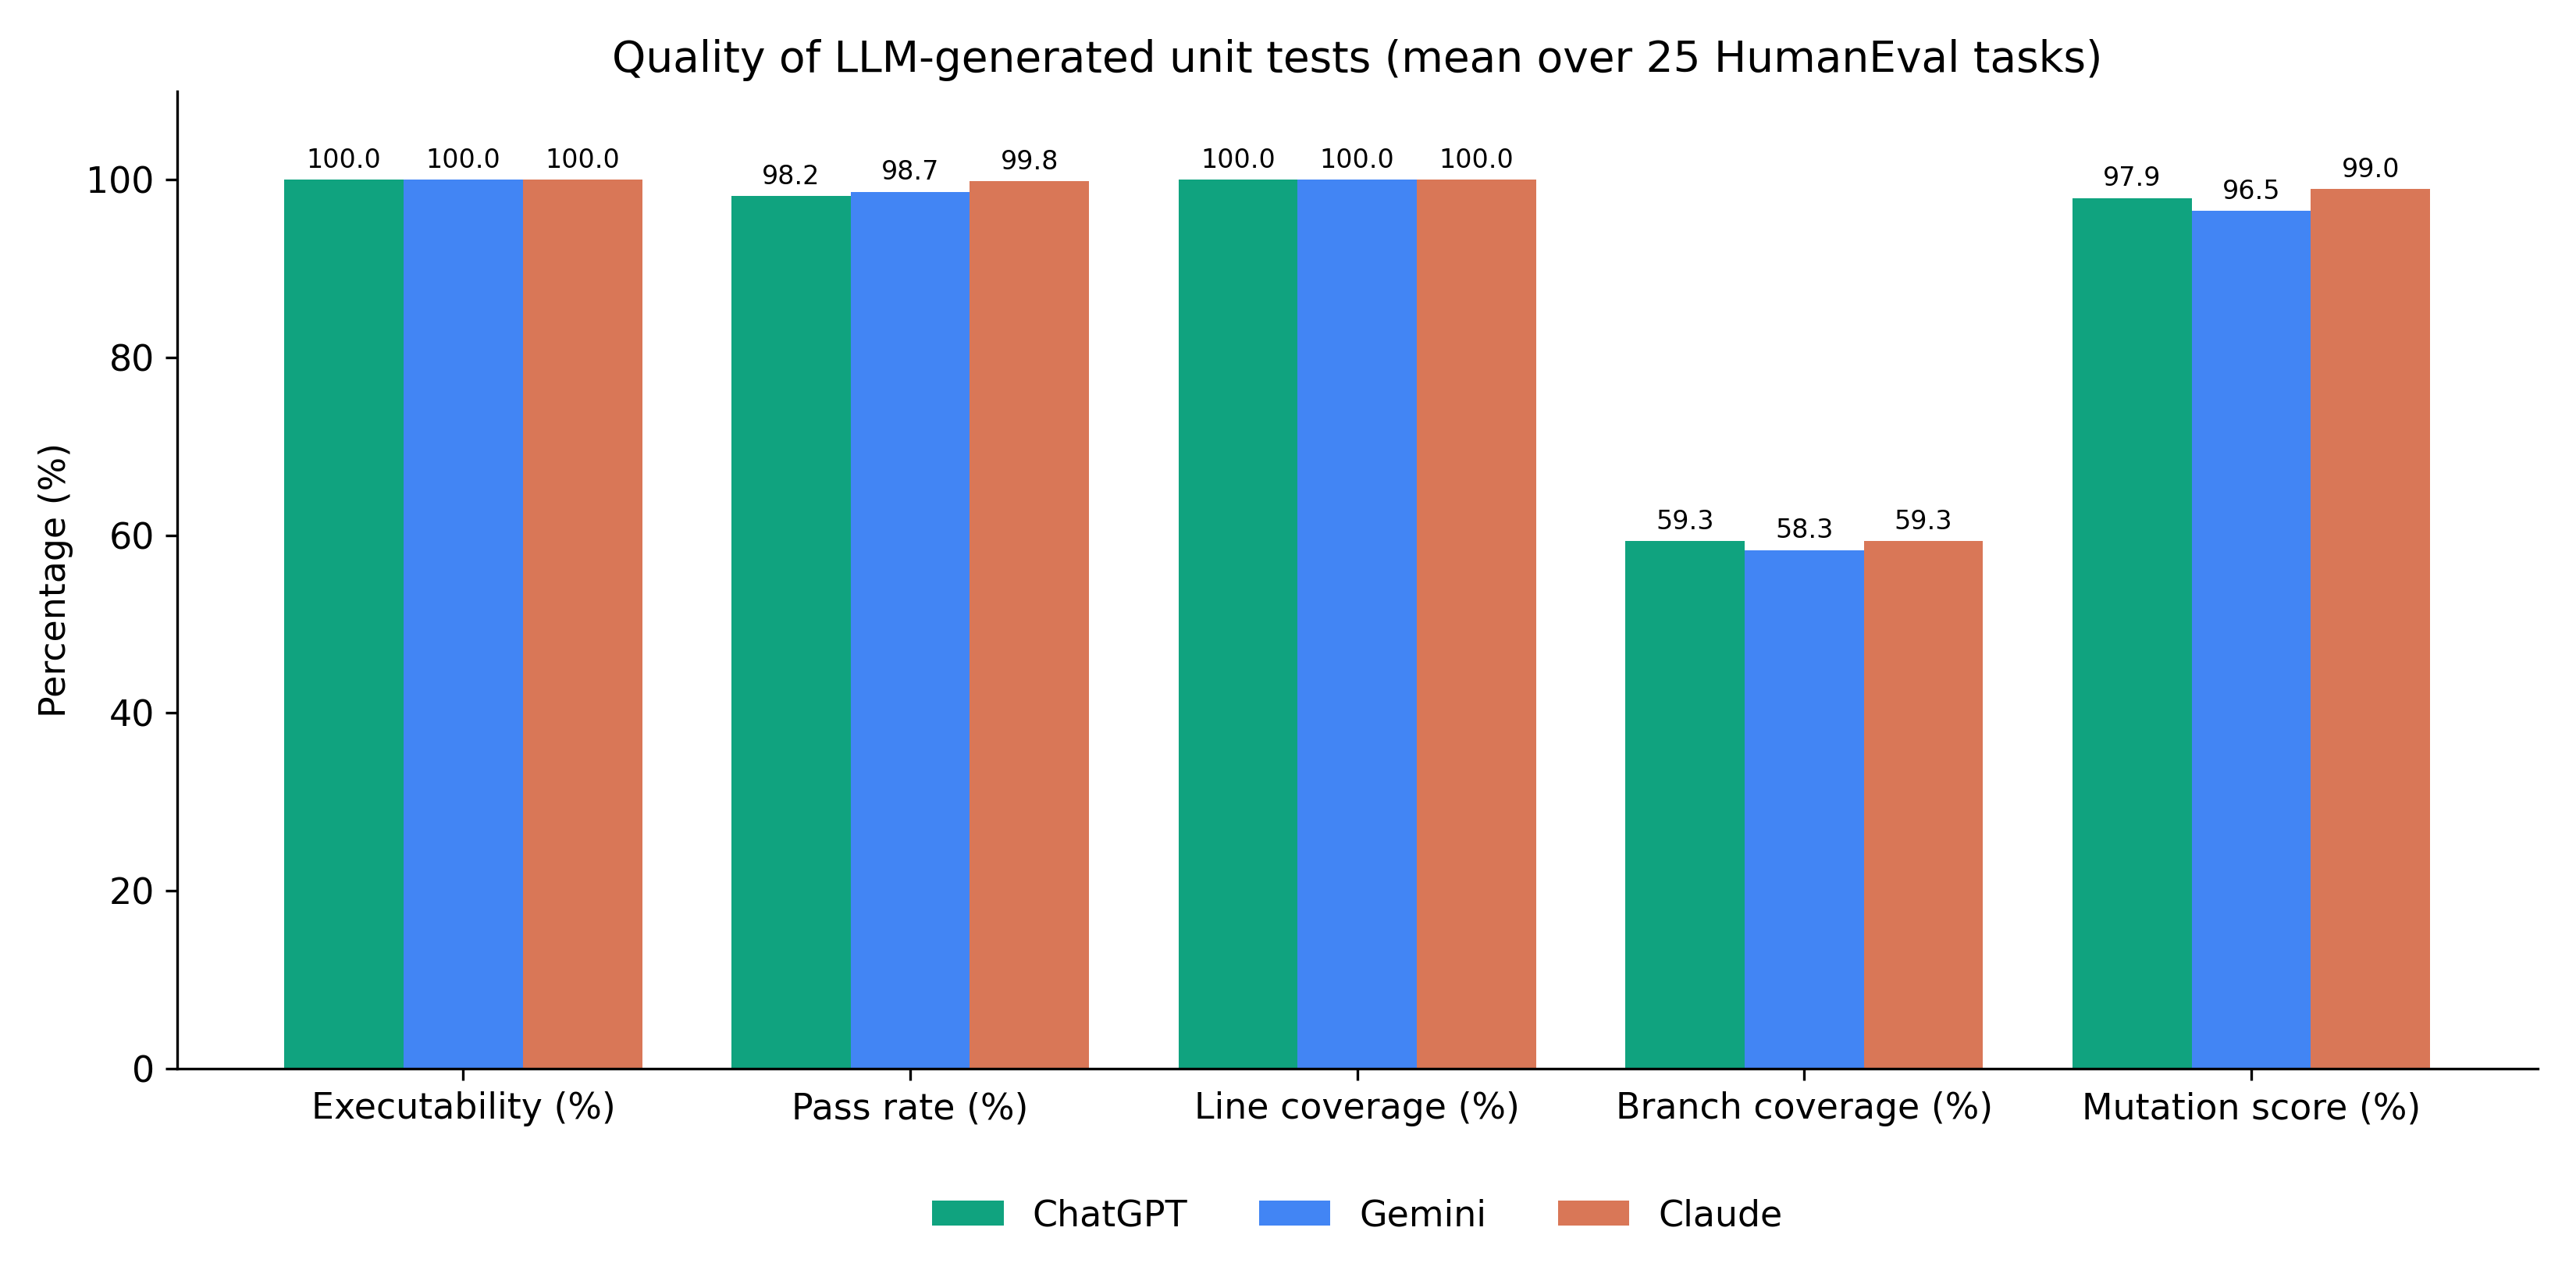

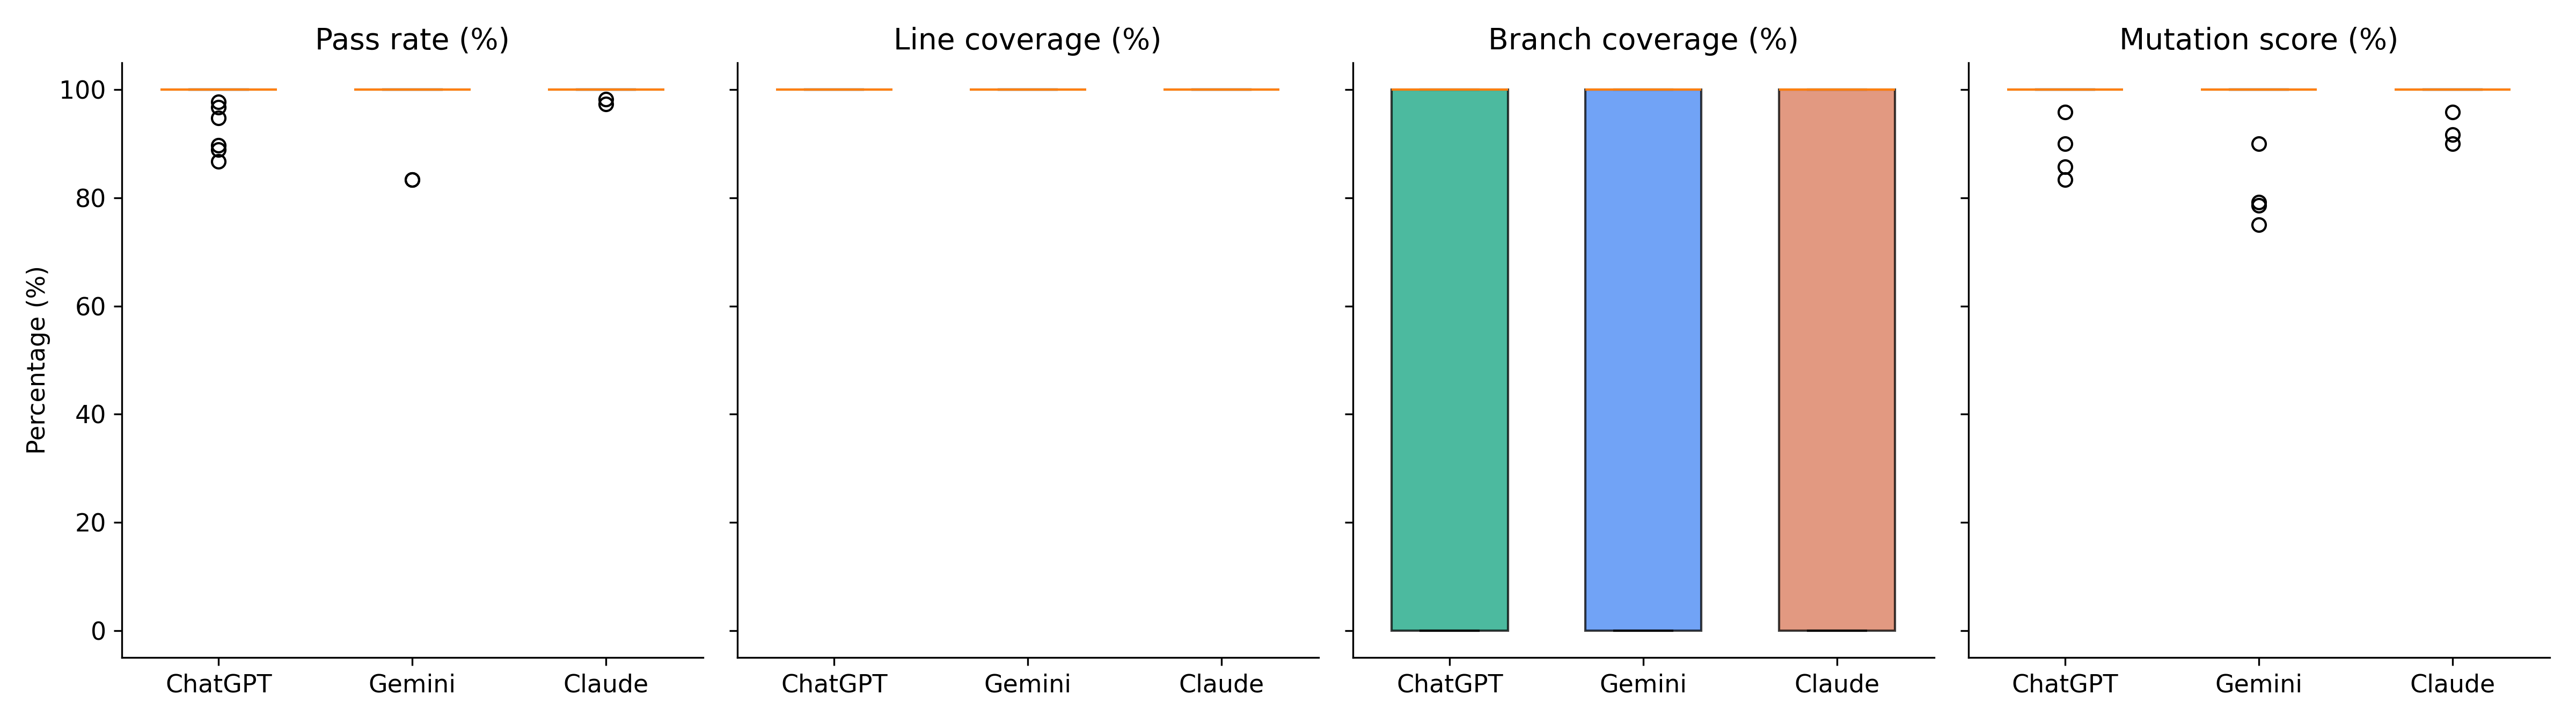

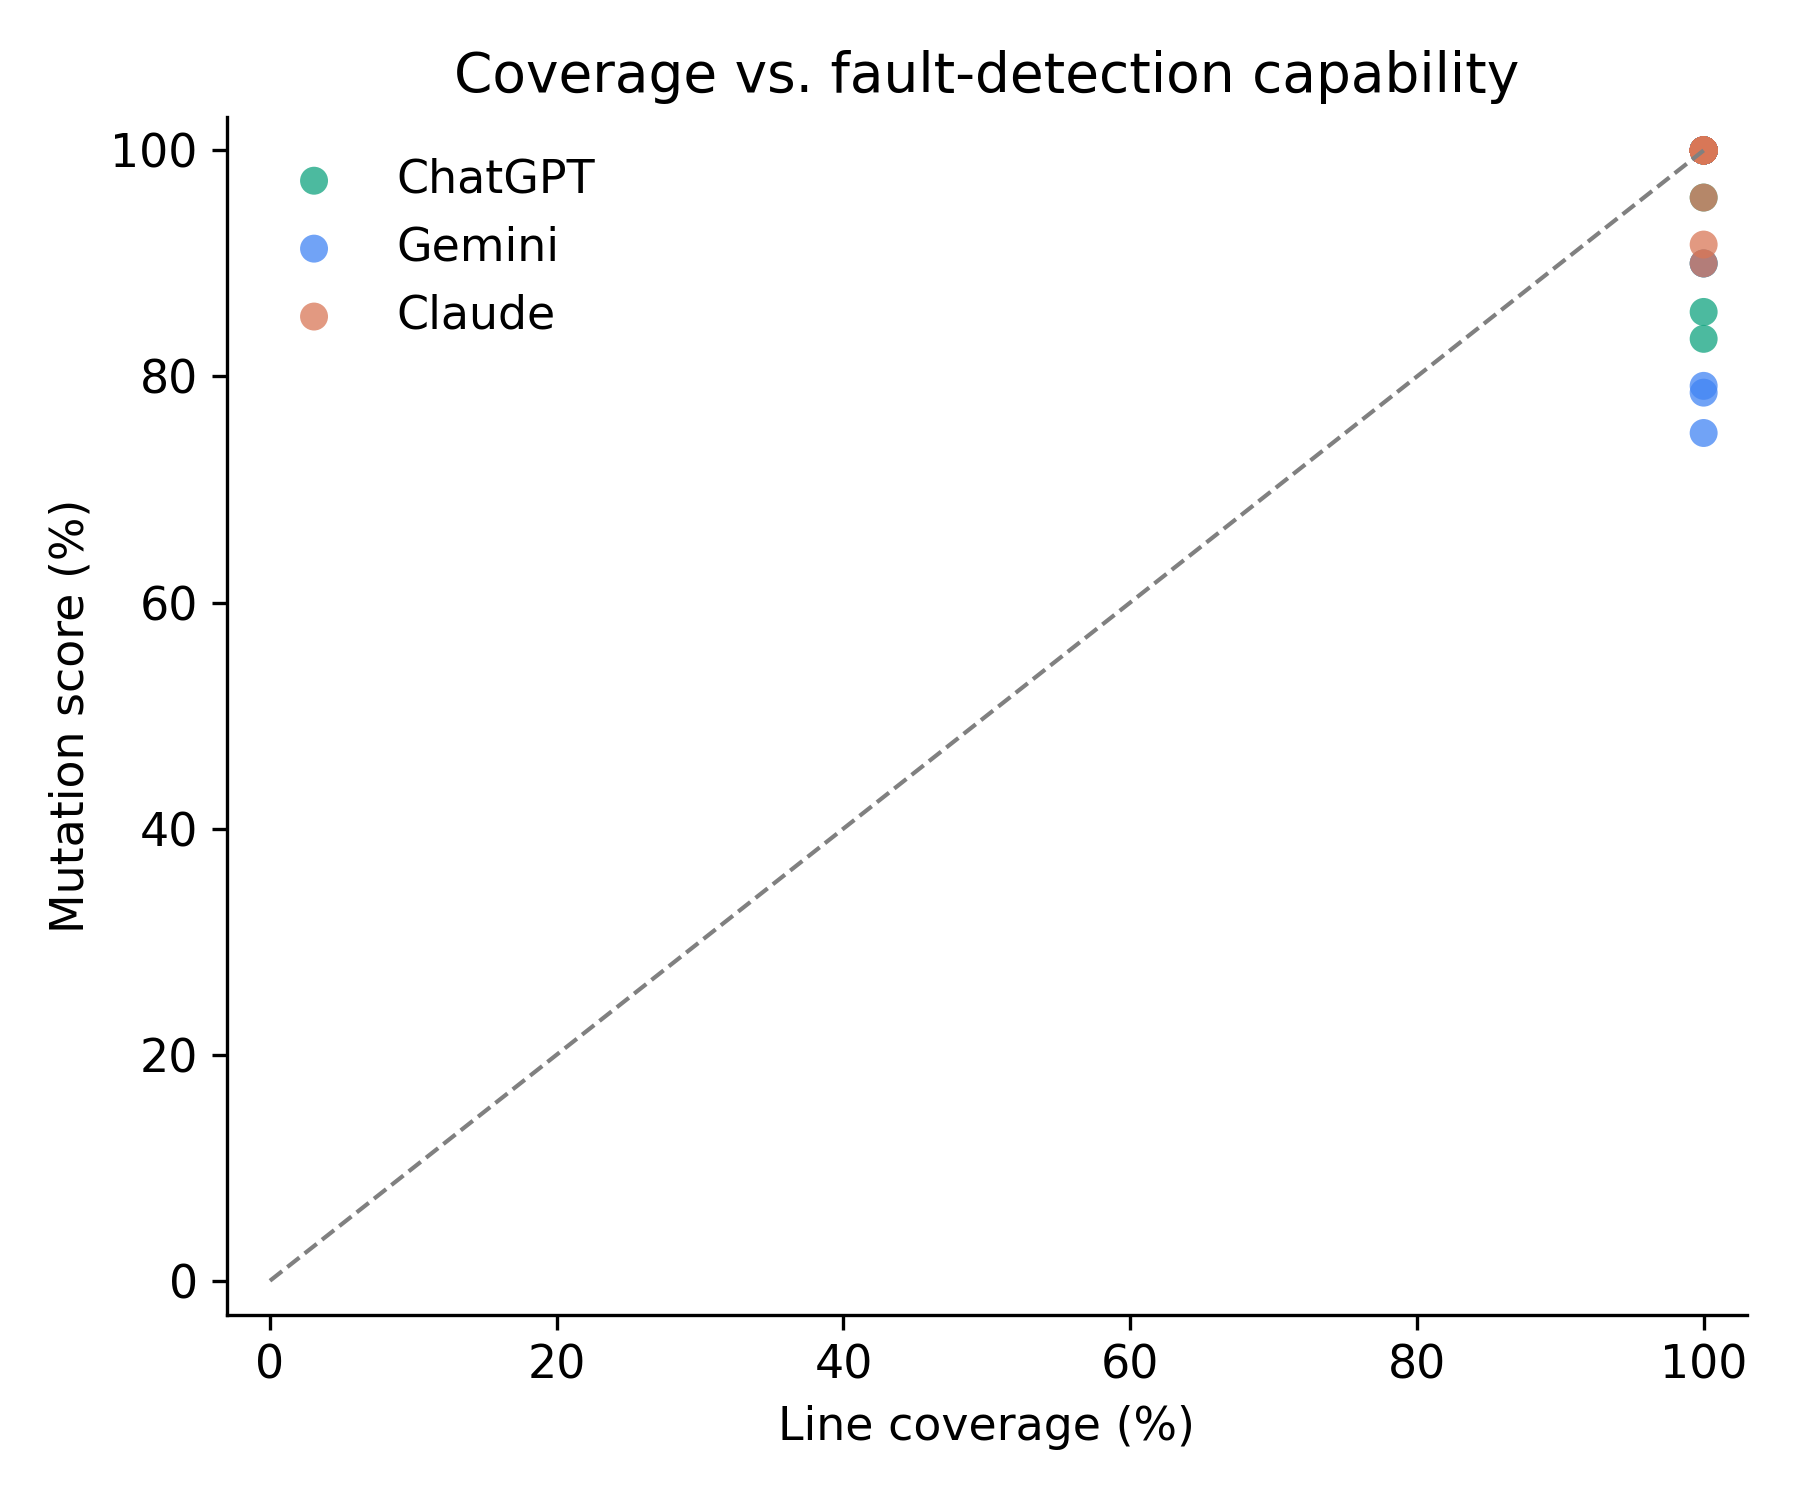

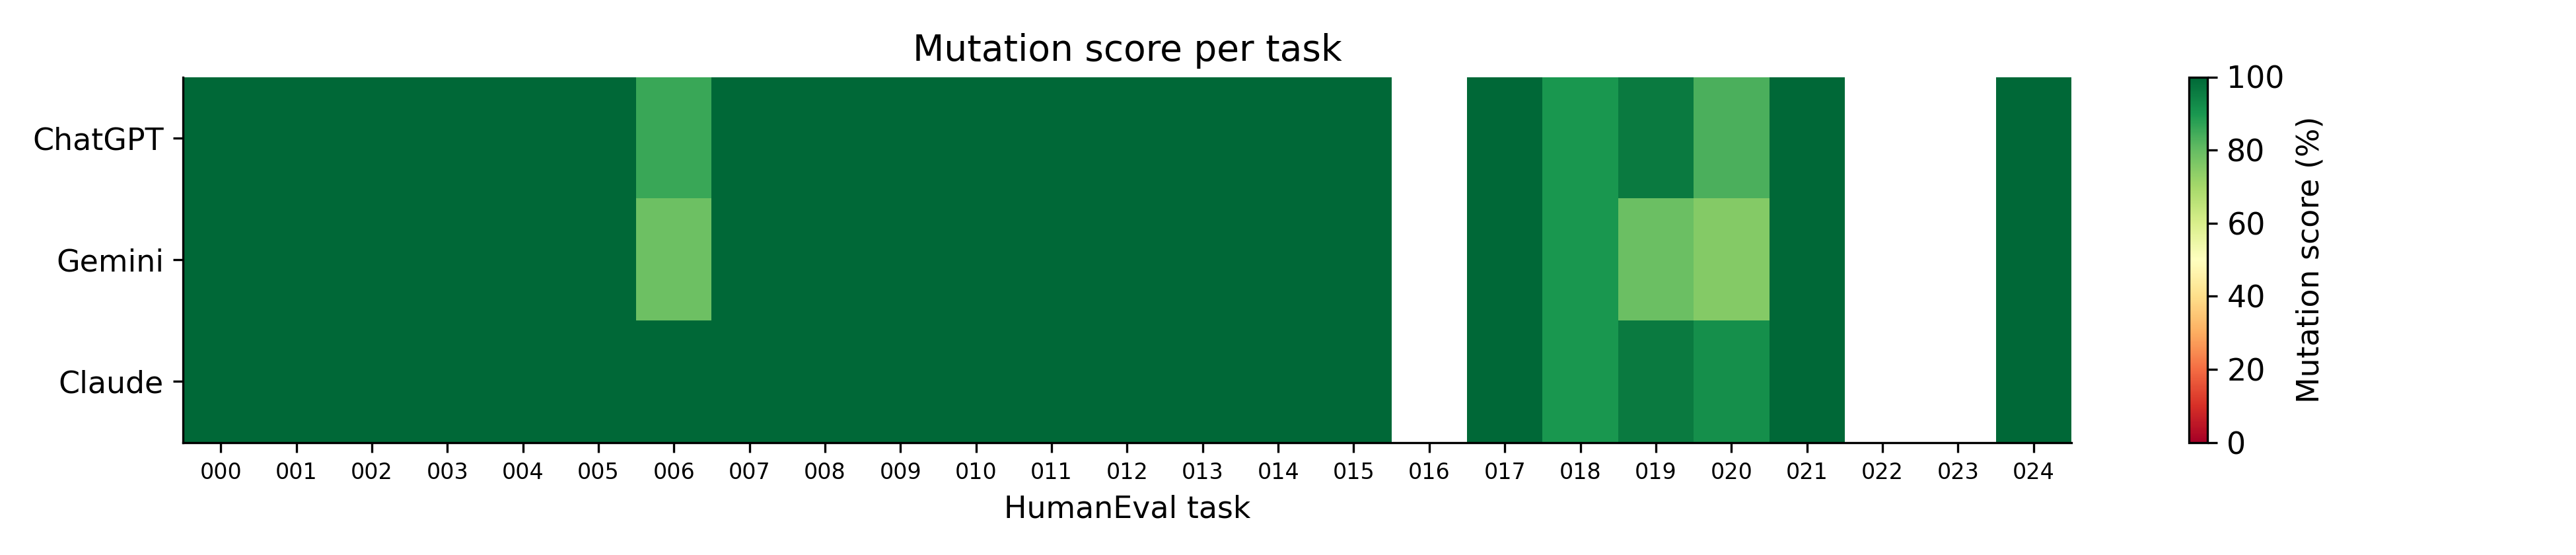

In [ ]:
# Run the visualization stage.
stage_plot(cfg)

# Import the Image display utility from IPython.
from IPython.display import Image

# Display all generated figures whose filenames start with "fig".
for f in sorted(cfg.figures_dir.glob('fig*.png')):
    display(Image(filename=str(f), width=800))